# Gradient Boosting Comparison

In [1]:
# imports

from pathlib import Path
import math

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import cross_val_score, GridSearchCV, StratifiedKFold


In [2]:
# paths

ROOT = Path.cwd()

while not (ROOT / "results" / "outputs").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent

ORIGINAL_DIR = ROOT / "results" / "outputs" / "original"
NEW_DIR = ROOT / "results" / "outputs" / "new"

RESULT_DIR = ROOT / "results" / "model_results" / "gradient_boosting"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)


Project root: /home/kashmira/git/crop-soil-fertilizer


In [3]:
# load data

original_train = pd.read_csv(ORIGINAL_DIR / "train_processed.csv")
original_test = pd.read_csv(ORIGINAL_DIR / "test_processed.csv")

new_train = pd.read_csv(NEW_DIR / "train_processed.csv")
new_test = pd.read_csv(NEW_DIR / "test_processed.csv")

original_mapping = pd.read_csv(ORIGINAL_DIR / "label_mapping.csv")
new_mapping = pd.read_csv(NEW_DIR / "label_mapping.csv")

print("Original train:", original_train.shape)
print("Original test:", original_test.shape)

print("\nNew train:", new_train.shape)
print("New test:", new_test.shape)


Original train: (6400, 24)
Original test: (1600, 24)

New train: (3610, 36)
New test: (903, 36)


In [4]:
# prepare data

target = "Target_Label"

X_train_original = original_train.drop(columns=[target])
y_train_original = original_train[target]

X_test_original = original_test.drop(columns=[target])
y_test_original = original_test[target]

X_train_new = new_train.drop(columns=[target])
y_train_new = new_train[target]

X_test_new = new_test.drop(columns=[target])
y_test_new = new_test[target]


In [5]:
# evaluation

def evaluate_gradient_boosting(
    name,
    X_train,
    y_train,
    X_test,
    y_test,
):
    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train, y_train)
    baseline_pred = baseline.predict(X_test)

    model = GradientBoostingClassifier(
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    cv_scores = cross_val_score(
        GradientBoostingClassifier(
            random_state=42
        ),
        X_train,
        y_train,
        cv=5,
        scoring="accuracy",
        n_jobs=-1,
    )

    result = {
        "Dataset": name,
        "Majority_Baseline": accuracy_score(y_test, baseline_pred),
        "Train_Accuracy": accuracy_score(y_train, train_pred),
        "Test_Accuracy": accuracy_score(y_test, test_pred),
        "Precision_Weighted": precision_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "Recall_Weighted": recall_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1_Weighted": f1_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1_Macro": f1_score(
            y_test,
            test_pred,
            average="macro",
            zero_division=0,
        ),
        "CV_Accuracy_Mean": cv_scores.mean(),
        "CV_Accuracy_Std": cv_scores.std(),
    }

    return model, test_pred, result


In [6]:
# train both datasets

original_model, original_pred, original_result = evaluate_gradient_boosting(
    "Original",
    X_train_original,
    y_train_original,
    X_test_original,
    y_test_original,
)

new_model, new_pred, new_result = evaluate_gradient_boosting(
    "New",
    X_train_new,
    y_train_new,
    X_test_new,
    y_test_new,
)

results = pd.DataFrame([
    original_result,
    new_result,
])

display(results.round(4))


,Dataset,Majority_Baseline,Train_Accuracy,Test_Accuracy,Precision_Weighted,Recall_Weighted,F1_Weighted,F1_Macro,CV_Accuracy_Mean,CV_Accuracy_Std
0,Original,0.1488,0.4450,0.1288,0.1264,0.1288,0.1269,0.1266,0.1378,0.0083
1,New,0.3023,0.7407,0.6124,0.6144,0.6124,0.6088,0.6988,0.5934,0.0095


In [7]:
# save results

results.to_csv(
    RESULT_DIR / "gradient_boosting_comparison.csv",
    index=False,
)

print("Saved:", RESULT_DIR / "gradient_boosting_comparison.csv")


Saved: /home/kashmira/git/crop-soil-fertilizer/results/model_results/gradient_boosting/gradient_boosting_comparison.csv


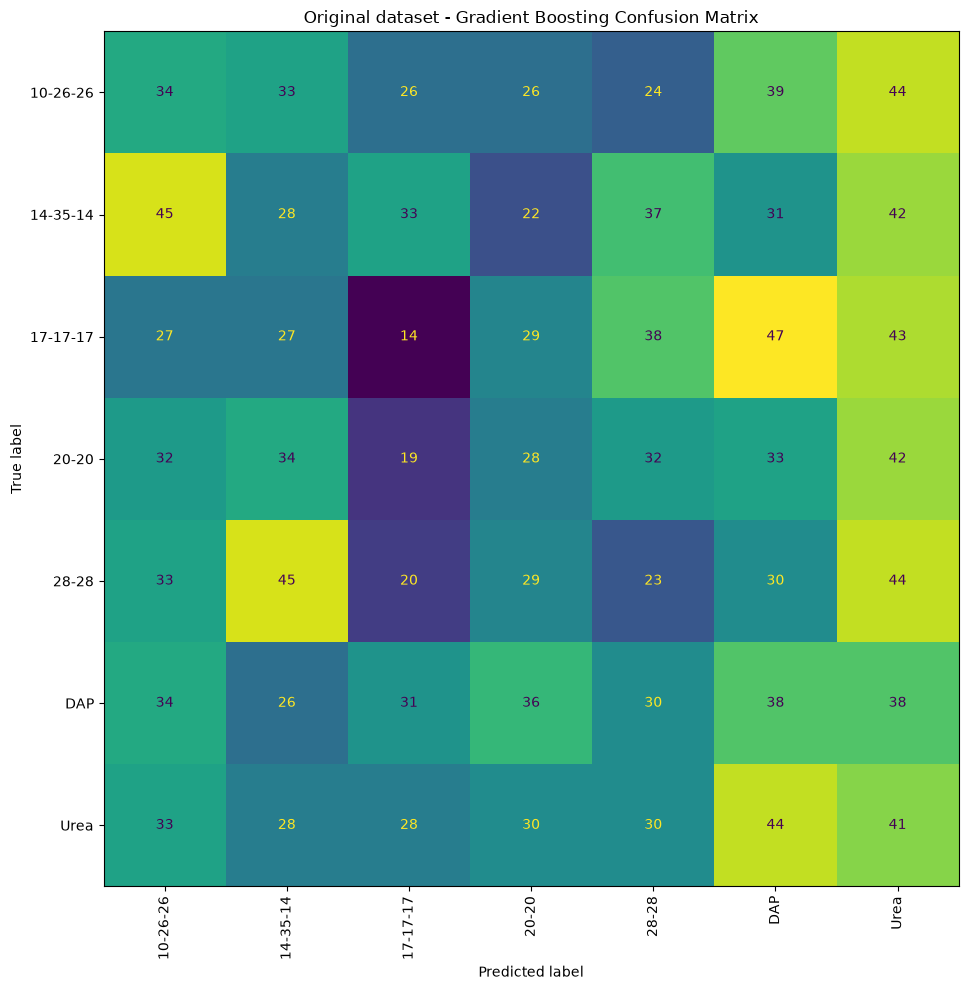

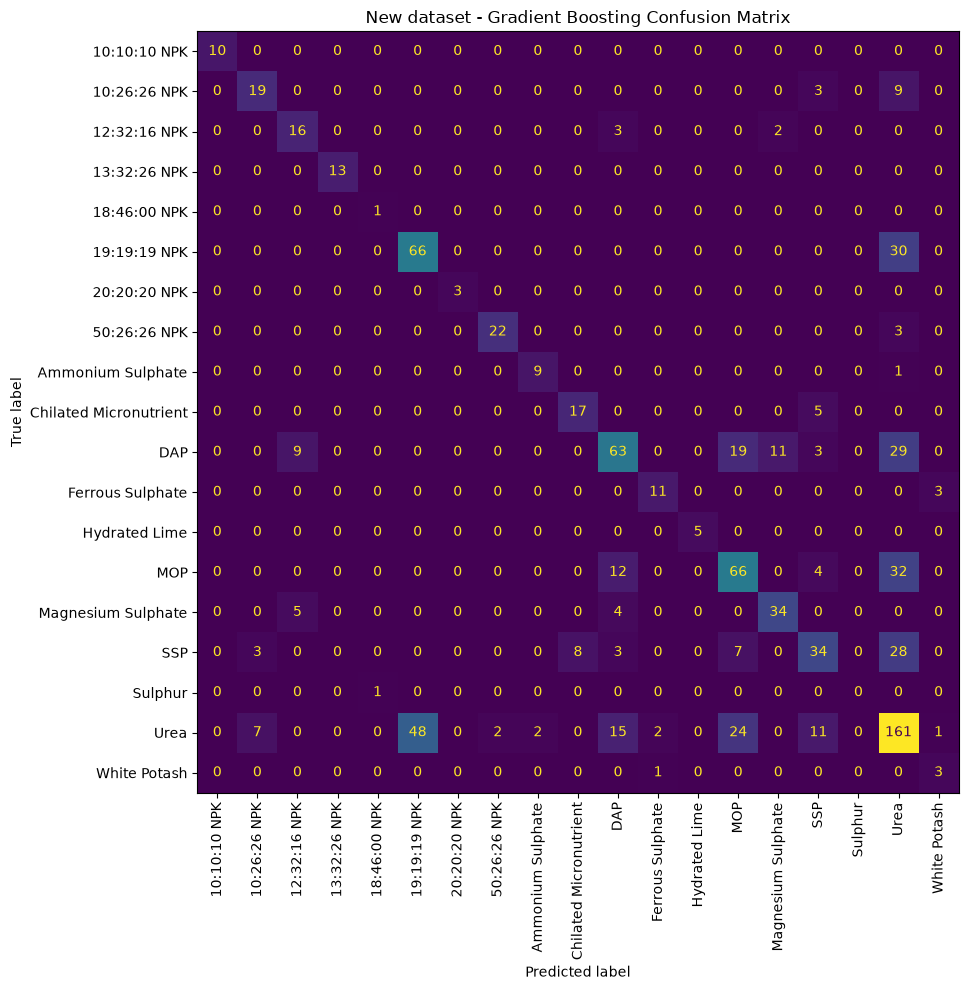

In [8]:
# confusion matrices

def plot_confusion_matrix(
    name,
    y_test,
    predictions,
    mapping,
    filename,
):
    labels = mapping["Target_Label"].tolist()
    names = mapping["Fertilizer"].tolist()

    fig, ax = plt.subplots(figsize=(12, 10))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=labels,
        display_labels=names,
        xticks_rotation=90,
        ax=ax,
        colorbar=False,
    )

    ax.set_title(f"{name} - Gradient Boosting Confusion Matrix")
    fig.tight_layout()
    fig.savefig(RESULT_DIR / filename, dpi=150)
    plt.show()

plot_confusion_matrix(
    "Original dataset",
    y_test_original,
    original_pred,
    original_mapping,
    "original_confusion_matrix.png",
)

plot_confusion_matrix(
    "New dataset",
    y_test_new,
    new_pred,
    new_mapping,
    "new_confusion_matrix.png",
)


In [9]:
# summary

for row in results.to_dict(orient="records"):
    print(f"\n{row['Dataset']} dataset")
    print(f"Baseline: {row['Majority_Baseline']:.4f}")
    print(f"Train accuracy: {row['Train_Accuracy']:.4f}")
    print(f"Test accuracy: {row['Test_Accuracy']:.4f}")
    print(f"Macro F1: {row['F1_Macro']:.4f}")
    print(f"Weighted F1: {row['F1_Weighted']:.4f}")
    print(f"5-fold CV accuracy: {row['CV_Accuracy_Mean']:.4f}")



Original dataset
Baseline: 0.1487
Train accuracy: 0.4450
Test accuracy: 0.1288
Macro F1: 0.1266
Weighted F1: 0.1269
5-fold CV accuracy: 0.1378

New dataset
Baseline: 0.3023
Train accuracy: 0.7407
Test accuracy: 0.6124
Macro F1: 0.6988
Weighted F1: 0.6088
5-fold CV accuracy: 0.5934


## Hyperparameter Tuning

We keep the group preprocessing fixed and compare multiple hyperparameter varieties using 5-fold stratified cross-validation on the training data. We select the best variety by macro F1 and evaluate the selected model on the held-out test set only after selection.

In [10]:
# tuning helper

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

def tune_model(
    dataset_name,
    estimator,
    param_grid,
    expected_candidates,
    X_train,
    y_train,
    X_test,
    y_test,
):
    candidate_count = math.prod(len(values) for values in param_grid.values())

    if candidate_count != expected_candidates:
        raise ValueError(
            f"Expected {expected_candidates} candidates, got {candidate_count}"
        )

    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
        error_score="raise",
    )

    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    train_pred = best_model.predict(X_train)
    test_pred = best_model.predict(X_test)

    tuning_results = pd.DataFrame(search.cv_results_)[[
        "params",
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score",
    ]].sort_values(
        ["rank_test_score", "mean_test_score"],
        ascending=[True, False],
    )

    result = {
        "Dataset": dataset_name,
        "Variant": "Tuned",
        "Candidate_Configurations": candidate_count,
        "Selection_Metric": "Macro F1",
        "Best_CV_Macro_F1": search.best_score_,
        "Train_Accuracy": accuracy_score(y_train, train_pred),
        "Test_Accuracy": accuracy_score(y_test, test_pred),
        "Precision_Weighted": precision_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "Recall_Weighted": recall_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1_Weighted": f1_score(
            y_test,
            test_pred,
            average="weighted",
            zero_division=0,
        ),
        "F1_Macro": f1_score(
            y_test,
            test_pred,
            average="macro",
            zero_division=0,
        ),
        "Best_Params": str(search.best_params_),
    }

    return search, best_model, test_pred, tuning_results, result


In [11]:
# parameter grid

param_grid = {
    "n_estimators": [50, 100],
    "learning_rate": [0.05, 0.1],
    "max_depth": [1, 3],
}

EXPECTED_CANDIDATES = 8

print("Candidate configurations:", math.prod(
    len(values) for values in param_grid.values()
))

original_search, original_tuned_model, original_tuned_pred, original_tuning_results, original_tuned_result = tune_model(
    "Original",
    GradientBoostingClassifier(
    random_state=42
),
    param_grid,
    EXPECTED_CANDIDATES,
    X_train_original,
    y_train_original,
    X_test_original,
    y_test_original,
)

new_search, new_tuned_model, new_tuned_pred, new_tuning_results, new_tuned_result = tune_model(
    "New",
    GradientBoostingClassifier(
    random_state=42
),
    param_grid,
    EXPECTED_CANDIDATES,
    X_train_new,
    y_train_new,
    X_test_new,
    y_test_new,
)

print("\nOriginal best parameters:")
print(original_search.best_params_)
print("Original best CV macro F1:", round(original_search.best_score_, 4))

print("\nNew best parameters:")
print(new_search.best_params_)
print("New best CV macro F1:", round(new_search.best_score_, 4))


Candidate configurations: 8



Original best parameters:
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Original best CV macro F1: 0.1405

New best parameters:
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
New best CV macro F1: 0.6677


In [12]:
# model varieties

print("Original top 5 varieties")
display(
    original_tuning_results.head(5).reset_index(drop=True)
)

print("New top 5 varieties")
display(
    new_tuning_results.head(5).reset_index(drop=True)
)


Original top 5 varieties


,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.379359,0.140471,0.011993,1
1,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.382415,0.140083,0.011428,2
2,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.486177,0.139500,0.006195,3
3,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti...",0.205849,0.138513,0.010370,4
4,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.304611,0.138399,0.014232,5


New top 5 varieties


,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.860233,0.667726,0.042934,1
1,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.817544,0.620066,0.050876,2
2,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.804068,0.604086,0.047024,3
3,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.754702,0.580798,0.020186,4
4,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti...",0.536509,0.390843,0.023186,5


In [13]:
# default vs tuned

default_results = results[[
    "Dataset",
    "Train_Accuracy",
    "Test_Accuracy",
    "Precision_Weighted",
    "Recall_Weighted",
    "F1_Weighted",
    "F1_Macro",
]].copy()

default_results.insert(1, "Variant", "Reference")
default_results["Candidate_Configurations"] = 1
default_results["Selection_Metric"] = "Reference model"
default_results["Best_CV_Macro_F1"] = pd.NA
default_results["Best_Params"] = "Reference configuration"

tuned_results = pd.DataFrame([
    original_tuned_result,
    new_tuned_result,
])

comparison = pd.concat(
    [default_results, tuned_results],
    ignore_index=True,
)

display(comparison.round(4))

comparison.to_csv(
    RESULT_DIR / "gradient_boosting_tuning_comparison.csv",
    index=False,
)

original_tuning_results.to_csv(
    RESULT_DIR / "original_tuning_results.csv",
    index=False,
)

new_tuning_results.to_csv(
    RESULT_DIR / "new_tuning_results.csv",
    index=False,
)


,Dataset,Variant,Train_Accuracy,Test_Accuracy,Precision_Weighted,Recall_Weighted,F1_Weighted,F1_Macro,Candidate_Configurations,Selection_Metric,Best_CV_Macro_F1,Best_Params
0,Original,Reference,0.4450,0.1288,0.1264,0.1288,0.1269,0.1266,1,Reference model,<NA>,Reference configuration
1,New,Reference,0.7407,0.6124,0.6144,0.6124,0.6088,0.6988,1,Reference model,<NA>,Reference configuration
2,Original,Tuned,0.3516,0.1331,0.1338,0.1331,0.1318,0.1316,8,Macro F1,0.140471,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est..."
3,New,Tuned,0.7407,0.6124,0.6144,0.6124,0.6088,0.6988,8,Macro F1,0.667726,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti..."


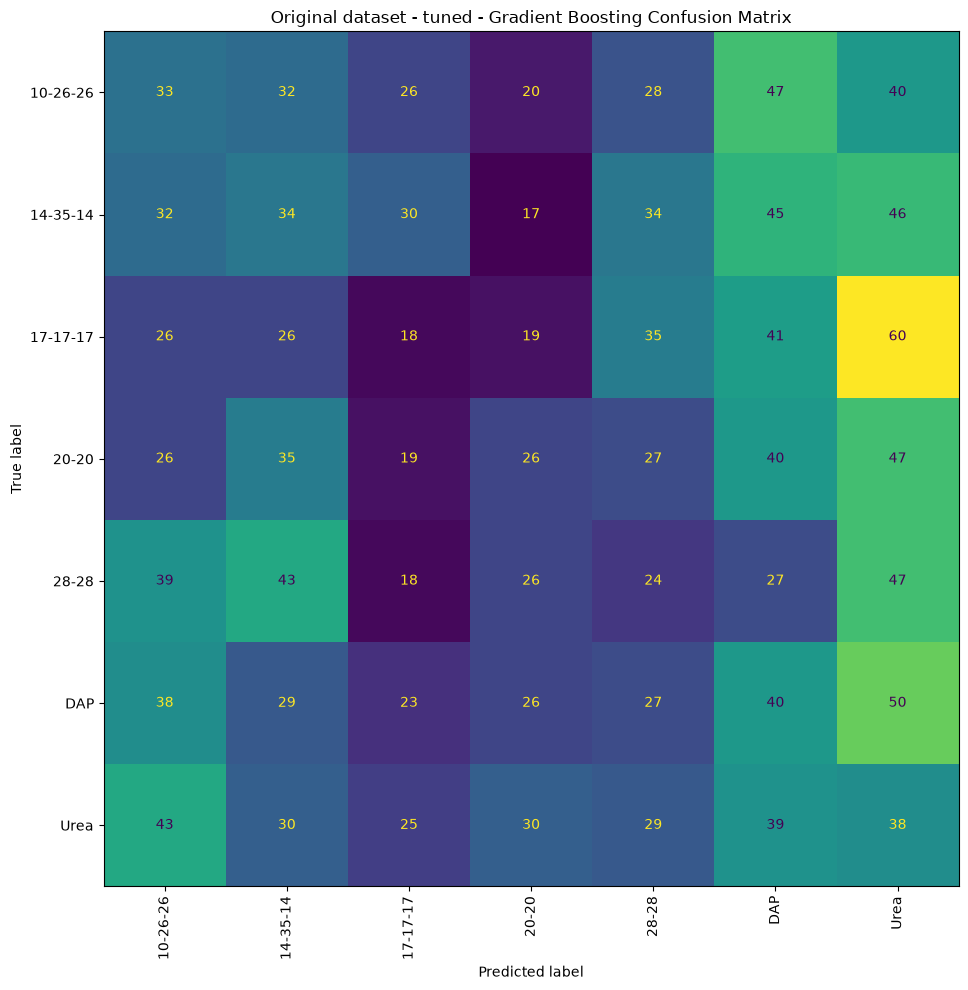

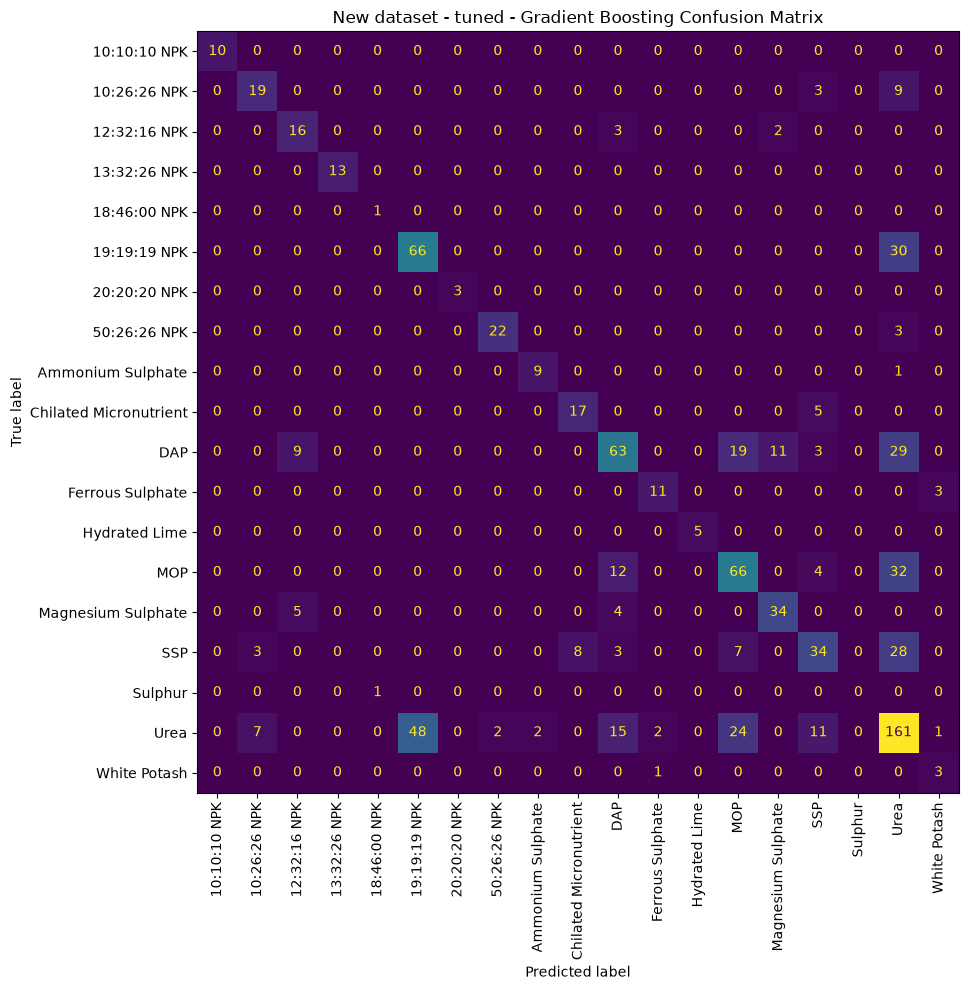

In [14]:
# tuned confusion matrices

plot_confusion_matrix(
    "Original dataset - tuned",
    y_test_original,
    original_tuned_pred,
    original_mapping,
    "original_tuned_confusion_matrix.png",
)

plot_confusion_matrix(
    "New dataset - tuned",
    y_test_new,
    new_tuned_pred,
    new_mapping,
    "new_tuned_confusion_matrix.png",
)


In [15]:
# tuned summary

for row in tuned_results.to_dict(orient="records"):
    print(f"\n{row['Dataset']} dataset")
    print(f"Varieties tested: {row['Candidate_Configurations']}")
    print(f"Selection metric: {row['Selection_Metric']}")
    print(f"Best parameters: {row['Best_Params']}")
    print(f"Best 5-fold CV macro F1: {row['Best_CV_Macro_F1']:.4f}")
    print(f"Test accuracy: {row['Test_Accuracy']:.4f}")
    print(f"Weighted F1: {row['F1_Weighted']:.4f}")
    print(f"Macro F1: {row['F1_Macro']:.4f}")



Original dataset
Varieties tested: 8
Selection metric: Macro F1
Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
Best 5-fold CV macro F1: 0.1405
Test accuracy: 0.1331
Weighted F1: 0.1318
Macro F1: 0.1316

New dataset
Varieties tested: 8
Selection metric: Macro F1
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Best 5-fold CV macro F1: 0.6677
Test accuracy: 0.6124
Weighted F1: 0.6088
Macro F1: 0.6988
